# Лабораторная работа №2
## «Подбор распределения модели надёжности и оценка параметров»

**Курс:** Модели надёжности АСОИУ
**Студент:** Пермяков Дмитрий Кириллович
**Группа:** ИУ5-22М
**Вариант:** 18

---

### Цель работы
По выборке наработок на отказ научиться:
1. подбирать наиболее подходящее распределение (нормальное, экспоненциальное, гамма, лог-нормальное, Рэлея, Вейбулла, Гумбеля);
2. оценивать параметры выбранного распределения (методом моментов и методом максимального правдоподобия);
3. строить и интерпретировать основные показатели надёжности — $P(t),\ Q(t),\ f(t),\ \lambda(t),\ T_0$;
4. понять, как объём выборки влияет на точность оценки параметров.

### Задание (две части)
- **Задание 1.** Для выборки времён наработки на отказ (500 значений, вариант 18) подобрать распределение и оценить параметры Вейбулла. Построить графики основных показателей надёжности.
- **Задание 2.** Для параметров Вейбулла из варианта ($a=19.3439$ — масштаб, $b=1.2146$ — форма) сгенерировать выборки размером 50, 100, 200, 500; для каждой оценить параметры и сравнить с истинными.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gamma as gammafn

VARIANT = 18
A_VAR   = 19.343873276596202   # масштаб распределения Вейбулла (вариант 18)
B_VAR   = 1.2145975470509338   # форма

np.random.seed(VARIANT)
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['axes.grid'] = True
print(f'Вариант: {VARIANT}, табличные параметры Вейбулла: a={A_VAR:.4f}, b={B_VAR:.4f}')


Вариант: 18, табличные параметры Вейбулла: a=19.3439, b=1.2146


## Краткая теория

**Показатели надёжности** для случайной величины «время до отказа» $\xi$ с плотностью $f(t)$:
- $Q(t)=P(\xi<t)$ — **вероятность отказа** (функция распределения, ФР).
- $P(t)=1-Q(t)=P(\xi\ge t)$ — **ВБР**, вероятность безотказной работы.
- $f(t)=\dfrac{dQ}{dt}$ — плотность вероятности отказа.
- $\lambda(t)=\dfrac{f(t)}{P(t)}$ — **интенсивность отказов** (failure rate).
- $T_0=E[\xi]=\int_0^\infty P(t)\,dt$ — **средняя наработка на отказ**.

**Распределение Вейбулла** (параметризация по методичке):
$$f(t)=\frac{b}{a}\Big(\frac{t}{a}\Big)^{b-1}\exp\!\Big[-\Big(\frac{t}{a}\Big)^b\Big],\quad t\ge0;\qquad Q(t)=1-\exp\!\Big[-\Big(\frac{t}{a}\Big)^b\Big].$$

Параметр $a$ — *масштаб* (характерное время до отказа), $b$ — *форма*:
- $b<1$ — интенсивность отказов **падает** (период приработки);
- $b=1$ — экспоненциальное распределение, $\lambda=$ const;
- $b>1$ — интенсивность отказов **растёт** (износ, старение); при $b\approx 3.5$ Вейбулл ≈ нормальное.

**Метод максимального правдоподобия (ММП)** для Вейбулла даёт уравнение на $b$:
$$\frac{1}{b}+\frac{1}{n}\sum_i\ln t_i - \frac{\sum_i t_i^b\ln t_i}{\sum_i t_i^b}=0,\qquad a=\Big(\frac{1}{n}\sum_i t_i^b\Big)^{1/b}.$$

**Критерий Колмогорова–Смирнова (KS)** — мера согласия эмпирической ФР $F_n(t)$ и теоретической $F(t)$:
$D_n=\sup_t |F_n(t)-F(t)|$. Чем меньше $D_n$ (и больше p-value), тем лучше подходит распределение.


## Задание 1. Подбор распределения и параметров для выборки варианта 18

### 1.1. Загрузка выборки и базовая статистика


In [2]:
df = pd.read_csv('var18_sample.csv')
x = df['t'].to_numpy()
n = len(x)

print(f'Объём выборки n = {n}')
print(f'min={x.min():.4f}, max={x.max():.4f}, размах={x.max()-x.min():.4f}')
print(f'mean={x.mean():.4f}, median={np.median(x):.4f}, std={x.std(ddof=1):.4f}')
print(f'асимметрия = {stats.skew(x):.4f}, эксцесс = {stats.kurtosis(x):.4f}')


Объём выборки n = 500
min=14.1503, max=19.7162, размах=5.5659
mean=17.5567, median=17.6933, std=1.0721
асимметрия = -0.7040, эксцесс = 0.2138


### 1.2. Шесть стандартных диаграмм выборки (по методичке)

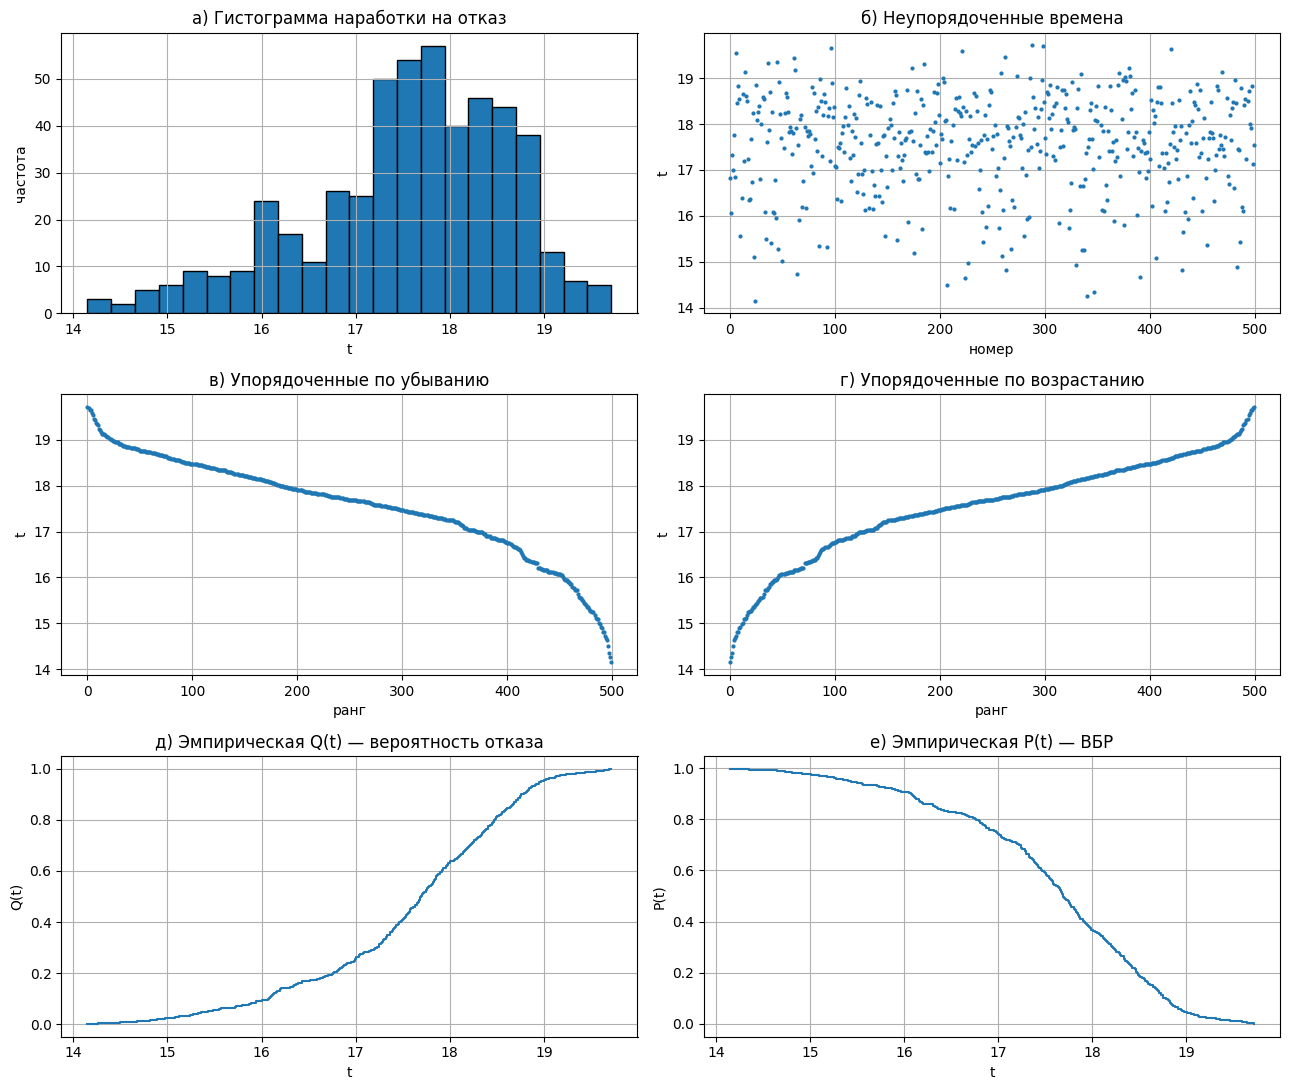

In [3]:
x_sort_asc  = np.sort(x)
x_sort_desc = np.sort(x)[::-1]
n = len(x)
P_emp = np.arange(1, n+1)/n   # эмпирическая ФР

fig, axes = plt.subplots(3, 2, figsize=(13, 11))

axes[0,0].hist(x, bins=int(np.sqrt(n)), edgecolor='black')
axes[0,0].set_title('а) Гистограмма наработки на отказ')
axes[0,0].set_xlabel('t'); axes[0,0].set_ylabel('частота')

axes[0,1].plot(x, 'o', ms=2)
axes[0,1].set_title('б) Неупорядоченные времена')
axes[0,1].set_xlabel('номер'); axes[0,1].set_ylabel('t')

axes[1,0].plot(x_sort_desc, 'o', ms=2)
axes[1,0].set_title('в) Упорядоченные по убыванию')
axes[1,0].set_xlabel('ранг'); axes[1,0].set_ylabel('t')

axes[1,1].plot(x_sort_asc, 'o', ms=2)
axes[1,1].set_title('г) Упорядоченные по возрастанию')
axes[1,1].set_xlabel('ранг'); axes[1,1].set_ylabel('t')

axes[2,0].step(x_sort_asc, P_emp, where='post')
axes[2,0].set_title('д) Эмпирическая Q(t) — вероятность отказа')
axes[2,0].set_xlabel('t'); axes[2,0].set_ylabel('Q(t)')

axes[2,1].step(x_sort_asc, 1-P_emp, where='post')
axes[2,1].set_title('е) Эмпирическая P(t) — ВБР')
axes[2,1].set_xlabel('t'); axes[2,1].set_ylabel('P(t)')

plt.tight_layout(); plt.show()


### 1.3. Проверка на нормальность
Два теста:
- **Простейший** — по доверительным интервалам для асимметрии $A_x$ и эксцесса $E_x$ (при нормальности оба должны быть около нуля);
- **Жарка–Бера** — комбинирует $A_x$ и $E_x$ в одну тестовую статистику.

Если p-value мало (< 0.05), нормальную гипотезу **отвергаем**.

In [4]:
Ax = stats.skew(x); Ex = stats.kurtosis(x)
Da = 6*(n-1)/((n+1)*(n+3))
De = 24*n*(n-2)*(n-3)/((n+1)**2*(n+3)*(n+5))
print(f'Асимметрия Ax = {Ax:.4f} (станд. ошибка ≈ {np.sqrt(Da):.4f})')
print(f'Эксцесс   Ex = {Ex:.4f} (станд. ошибка ≈ {np.sqrt(De):.4f})')
# 95% доверительные интервалы
for q in (0.10, 0.05, 0.01):
    z = stats.norm.ppf(1-q/2)
    a_lo,a_hi = Ax - z*np.sqrt(Da), Ax + z*np.sqrt(Da)
    e_lo,e_hi = Ex - z*np.sqrt(De), Ex + z*np.sqrt(De)
    norm_ok = (a_lo<=0<=a_hi) and (e_lo<=0<=e_hi)
    print(f'  q={q*100:.0f}%: A ∈ [{a_lo:+.3f},{a_hi:+.3f}], E ∈ [{e_lo:+.3f},{e_hi:+.3f}]  → '
          f'{"нормально" if norm_ok else "НЕ нормально"}')

jb = stats.jarque_bera(x)
print(f'\nЖарка–Бера: stat = {jb.statistic:.3f}, p-value = {jb.pvalue:.5f}')
print('Гипотеза о нормальности', 'отвергается' if jb.pvalue<0.05 else 'принимается')


Асимметрия Ax = -0.7040 (станд. ошибка ≈ 0.1090)
Эксцесс   Ex = 0.2138 (станд. ошибка ≈ 0.2158)
  q=10%: A ∈ [-0.883,-0.525], E ∈ [-0.141,+0.569]  → НЕ нормально
  q=5%: A ∈ [-0.918,-0.490], E ∈ [-0.209,+0.637]  → НЕ нормально
  q=1%: A ∈ [-0.985,-0.423], E ∈ [-0.342,+0.770]  → НЕ нормально

Жарка–Бера: stat = 42.256, p-value = 0.00000
Гипотеза о нормальности отвергается


### 1.4. Подбор распределения — параметры по ММП для нескольких семейств

In [5]:
# Кандидаты: имя в scipy, имя по-русски, аргументы fit
candidates = [
    ('norm',        'нормальное',   {}),
    ('expon',       'экспоненциальное', {'floc':0}),
    ('gamma',       'гамма',        {'floc':0}),
    ('lognorm',     'логнормальное',{'floc':0}),
    ('rayleigh',    'рэлеевское',   {'floc':0}),
    ('weibull_min', 'вейбулловское',{'floc':0}),
    ('gumbel_r',    'гамбеловское', {}),
]

results = []
for name, ru, kw in candidates:
    dist = getattr(stats, name)
    params = dist.fit(x, **kw)
    ks = stats.kstest(x, name, args=params)
    results.append({'name': name, 'ru': ru, 'params': params,
                    'D': ks.statistic, 'p': ks.pvalue})

df_res = pd.DataFrame(results).sort_values('p', ascending=False).reset_index(drop=True)
print('Подбор распределений (отсортировано по p-value KS-критерия):')
for _, r in df_res.iterrows():
    p_str = ', '.join(f'{v:.4f}' for v in r['params'])
    print(f"  {r['ru']:<16s} D={r['D']:.4f}  p={r['p']:.5f}  параметры=({p_str})")

best = df_res.iloc[0]
print(f"\nЛучшее распределение: {best['ru']} (p = {best['p']:.4f})")


Подбор распределений (отсортировано по p-value KS-критерия):
  вейбулловское    D=0.0320  p=0.67148  параметры=(20.1862, 0.0000, 18.0318)
  нормальное       D=0.0829  p=0.00196  параметры=(17.5567, 1.0711)
  гамма            D=0.0920  p=0.00039  параметры=(259.7230, 0.0000, 0.0676)
  логнормальное    D=0.0966  p=0.00016  параметры=(0.0626, 0.0000, 17.5229)
  гамбеловское     D=0.1432  p=0.00000  параметры=(16.9883, 1.2032)
  рэлеевское       D=0.4947  p=0.00000  параметры=(0.0000, 12.4375)
  экспоненциальное D=0.5578  p=0.00000  параметры=(0.0000, 17.5567)

Лучшее распределение: вейбулловское (p = 0.6715)


### 1.5. Оценка параметров Вейбулла двумя способами: ММП и метод моментов

In [6]:
# (А) ММП через scipy (фиксируем loc=0, чтобы получить «классические» a и b)
c_mle, loc_mle, scale_mle = stats.weibull_min.fit(x, floc=0)
b_mle, a_mle = c_mle, scale_mle
print(f'ММП:           a = {a_mle:.4f}, b = {b_mle:.4f}')

# (Б) Метод моментов: решаем относительно b уравнение
#   (sigma/mean)^2 = Gamma(1+2/b)/Gamma(1+1/b)^2 - 1, затем a = mean / Gamma(1+1/b)
mu, sigma = x.mean(), x.std(ddof=1)
cv2 = (sigma/mu)**2

from scipy.optimize import brentq
def f_b(b): return gammafn(1+2/b)/gammafn(1+1/b)**2 - 1 - cv2
b_mom = brentq(f_b, 0.05, 200)
a_mom = mu / gammafn(1+1/b_mom)
print(f'Метод моментов: a = {a_mom:.4f}, b = {b_mom:.4f}')

print(f'\nТабличные параметры варианта (Задание 2): a = {A_VAR:.4f}, b = {B_VAR:.4f}')
print('(они относятся к Заданию 2, а не к выборке выше — для выборки они отличаются.)')


ММП:           a = 18.0318, b = 20.1862
Метод моментов: a = 18.0277, b = 20.3073

Табличные параметры варианта (Задание 2): a = 19.3439, b = 1.2146
(они относятся к Заданию 2, а не к выборке выше — для выборки они отличаются.)


### 1.6. Эмпирическая плотность и наложенные теоретические PDF

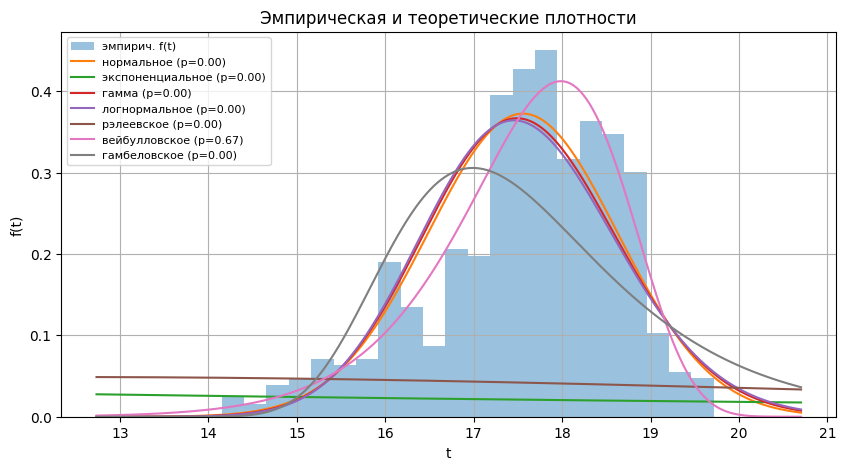

In [7]:
xx = np.linspace(x.min()*0.9, x.max()*1.05, 600)
plt.figure(figsize=(10,5))
plt.hist(x, bins=int(np.sqrt(n)), density=True, alpha=0.45, label='эмпирич. f(t)')

for r in results:
    dist = getattr(stats, r['name'])
    pdf  = dist.pdf(xx, *r['params'])
    plt.plot(xx, pdf, lw=1.5, label=f"{r['ru']} (p={r['p']:.2f})")
plt.title('Эмпирическая и теоретические плотности')
plt.xlabel('t'); plt.ylabel('f(t)')
plt.legend(fontsize=8, loc='upper left')
plt.show()


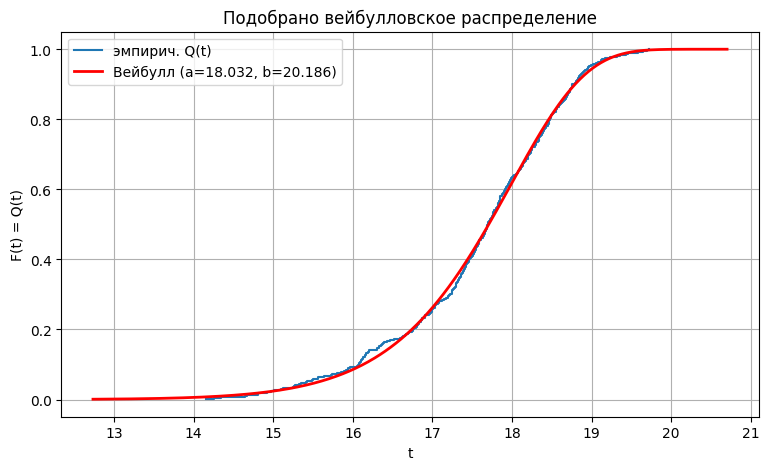

In [8]:
# Графика подобранного Вейбулла на эмпирической ФР
plt.figure()
plt.step(x_sort_asc, P_emp, where='post', label='эмпирич. Q(t)')
plt.plot(xx, stats.weibull_min.cdf(xx, b_mle, 0, a_mle), 'r-', lw=2,
         label=f'Вейбулл (a={a_mle:.3f}, b={b_mle:.3f})')
plt.title(f'Подобрано {best["ru"]} распределение')
plt.xlabel('t'); plt.ylabel('F(t) = Q(t)')
plt.legend(); plt.show()


### 1.7. Показатели надёжности для подобранной модели Вейбулла
$P(t),\ Q(t),\ f(t),\ \lambda(t)$ и средняя наработка $T_0=a\,\Gamma(1+1/b)$.

T0 (средняя наработка на отказ) = 17.5580


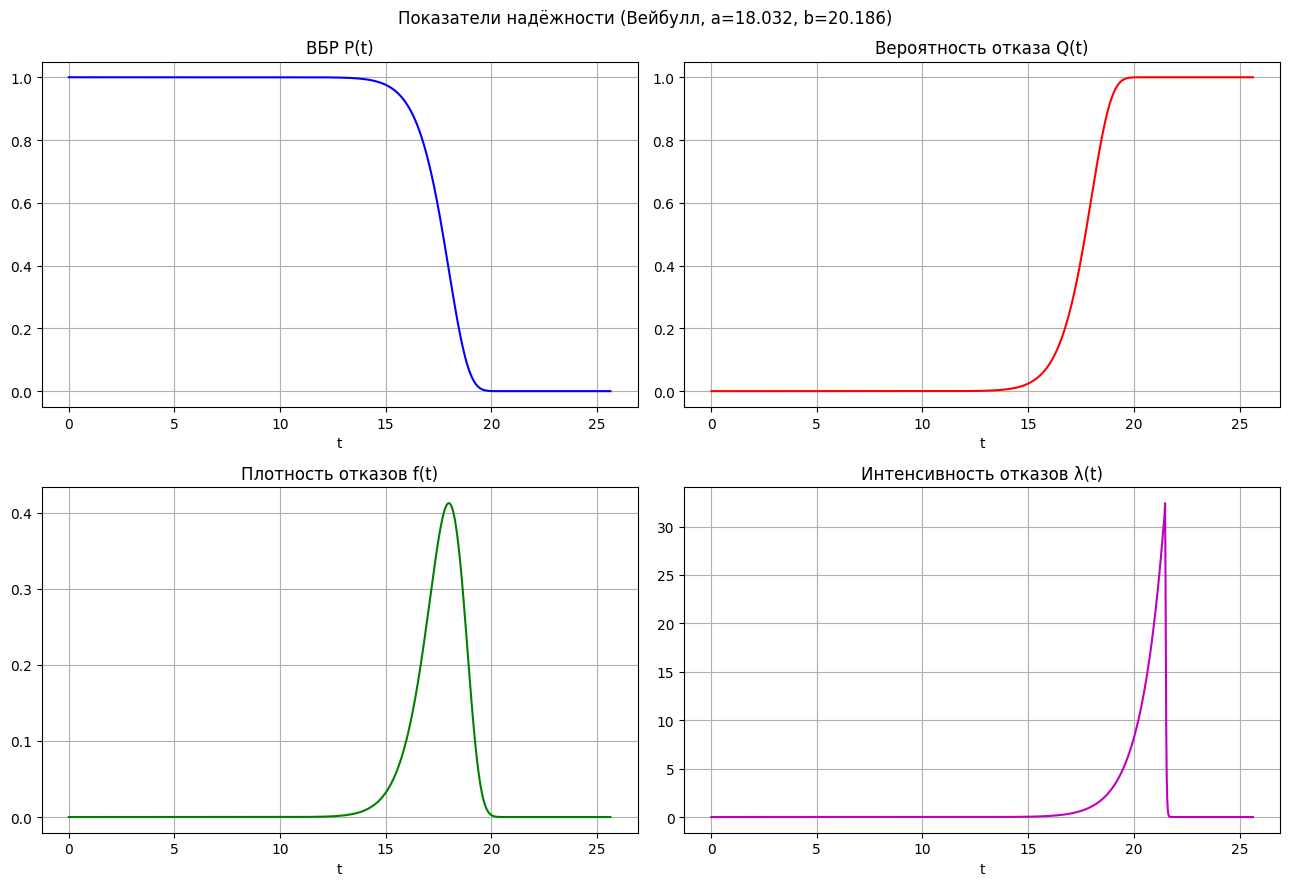

In [9]:
a_hat, b_hat = a_mle, b_mle
t = np.linspace(0.01, x.max()*1.3, 1000)
Q = 1 - np.exp(-(t/a_hat)**b_hat)
P = 1 - Q
f = (b_hat/a_hat)*(t/a_hat)**(b_hat-1)*np.exp(-(t/a_hat)**b_hat)
lam = f/np.clip(P, 1e-15, None)
T0 = a_hat * gammafn(1 + 1/b_hat)
print(f'T0 (средняя наработка на отказ) = {T0:.4f}')

fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0,0].plot(t, P, 'b'); ax[0,0].set_title('ВБР P(t)'); ax[0,0].set_xlabel('t')
ax[0,1].plot(t, Q, 'r'); ax[0,1].set_title('Вероятность отказа Q(t)'); ax[0,1].set_xlabel('t')
ax[1,0].plot(t, f, 'g'); ax[1,0].set_title('Плотность отказов f(t)'); ax[1,0].set_xlabel('t')
ax[1,1].plot(t, lam, 'm'); ax[1,1].set_title('Интенсивность отказов λ(t)'); ax[1,1].set_xlabel('t')
plt.suptitle(f'Показатели надёжности (Вейбулл, a={a_hat:.3f}, b={b_hat:.3f})')
plt.tight_layout(); plt.show()


## Задание 2. Влияние объёма выборки на точность оценки параметров

Берём истинные параметры Вейбулла **из таблицы варианта**:
$$a=19.3439,\qquad b=1.2146.$$
Генерируем синтетические выборки размеров $n\in\{50,100,200,500\}$, для каждой оцениваем параметры. Чтобы понять, насколько оценка устойчива, повторяем эксперимент **много раз** (Монте-Карло) и смотрим на:
- **смещение (bias)** — среднее отклонение оценки от истины;
- **СКО оценки (std)** — её разброс;
- **относительную ошибку** оценок.


In [10]:
# Истинные параметры варианта
a_true, b_true = A_VAR, B_VAR

sample_sizes = [50, 100, 200, 500]
n_runs = 500     # сколько раз повторяем эксперимент для каждого n

rng = np.random.default_rng(VARIANT)
rows = []
estimates = {n: [] for n in sample_sizes}
for nn in sample_sizes:
    for _ in range(n_runs):
        sample = stats.weibull_min.rvs(b_true, loc=0, scale=a_true, size=nn, random_state=rng)
        c_, _, s_ = stats.weibull_min.fit(sample, floc=0)
        estimates[nn].append((s_, c_))    # (a_hat, b_hat)

# Сводная таблица
for nn in sample_sizes:
    arr = np.array(estimates[nn])
    a_hat, b_hat = arr[:,0], arr[:,1]
    rows.append({'n':nn,
                 'a_mean':a_hat.mean(), 'a_std':a_hat.std(ddof=1),
                 'b_mean':b_hat.mean(), 'b_std':b_hat.std(ddof=1),
                 'a_bias%': (a_hat.mean()-a_true)/a_true*100,
                 'b_bias%': (b_hat.mean()-b_true)/b_true*100,
                 'a_relSE%': a_hat.std(ddof=1)/a_true*100,
                 'b_relSE%': b_hat.std(ddof=1)/b_true*100})

df_acc = pd.DataFrame(rows).set_index('n')
pd.options.display.float_format = '{:,.4f}'.format
print(f'Истинные параметры: a={a_true:.4f}, b={b_true:.4f}')
print(f'Число повторов на каждый n: {n_runs}\n')
print(df_acc)


Истинные параметры: a=19.3439, b=1.2146
Число повторов на каждый n: 500

     a_mean  a_std  b_mean  b_std  a_bias%  b_bias%  a_relSE%  b_relSE%
n                                                                      
50  19.3583 2.5414  1.2463 0.1438   0.0748   2.6088   13.1382   11.8386
100 19.2075 1.6739  1.2253 0.1000  -0.7051   0.8783    8.6532    8.2344
200 19.4299 1.1649  1.2209 0.0693   0.4447   0.5151    6.0222    5.7095
500 19.2912 0.7667  1.2175 0.0422  -0.2725   0.2383    3.9637    3.4735


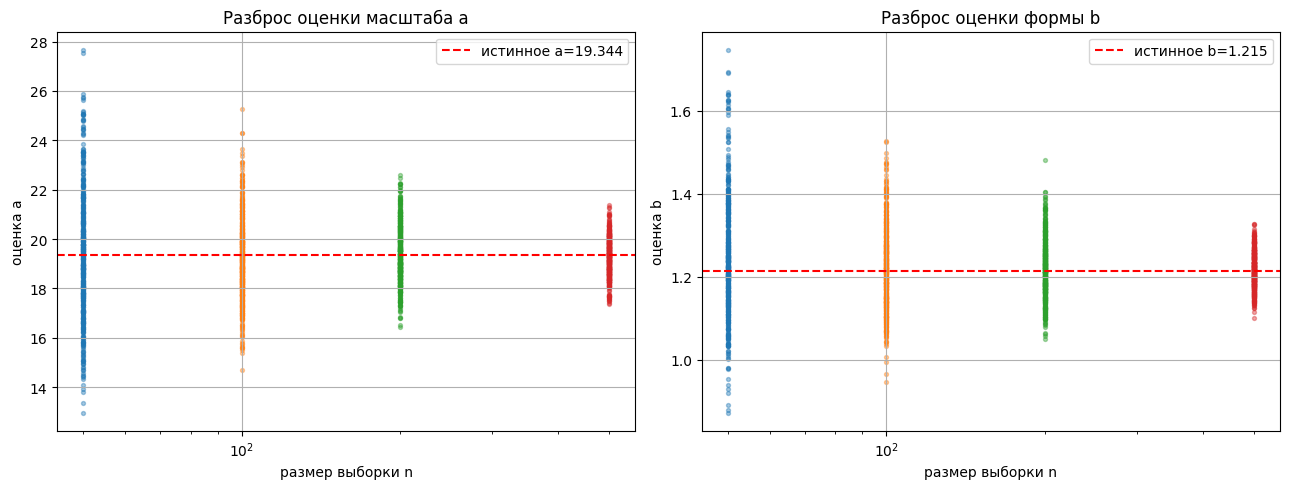

In [11]:
# Графики: разброс оценок параметров от объёма выборки
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nn in sample_sizes:
    arr = np.array(estimates[nn])
    ax[0].scatter([nn]*len(arr), arr[:,0], s=8, alpha=0.4)
    ax[1].scatter([nn]*len(arr), arr[:,1], s=8, alpha=0.4)
ax[0].axhline(a_true, color='r', ls='--', label=f'истинное a={a_true:.3f}')
ax[1].axhline(b_true, color='r', ls='--', label=f'истинное b={b_true:.3f}')
ax[0].set_xlabel('размер выборки n'); ax[0].set_ylabel('оценка a')
ax[1].set_xlabel('размер выборки n'); ax[1].set_ylabel('оценка b')
ax[0].set_xscale('log'); ax[1].set_xscale('log')
ax[0].set_title('Разброс оценки масштаба a'); ax[0].legend()
ax[1].set_title('Разброс оценки формы b');    ax[1].legend()
plt.tight_layout(); plt.show()


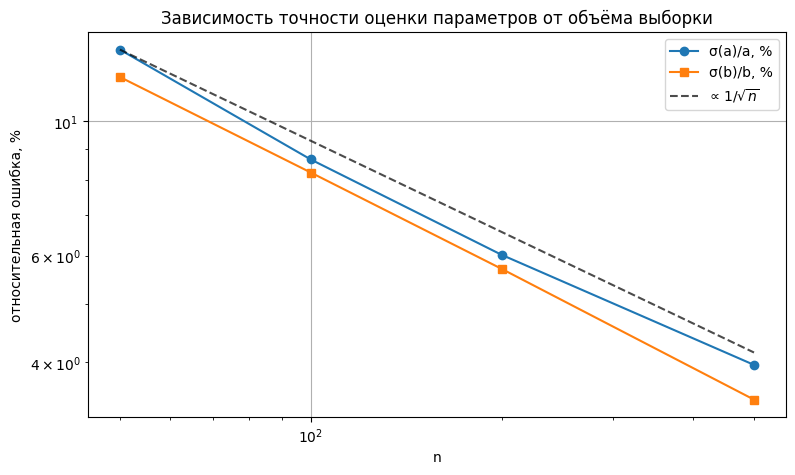

In [12]:
# Относительные ошибки vs n
plt.figure()
plt.loglog(df_acc.index, df_acc['a_relSE%'], 'o-', label='σ(a)/a, %')
plt.loglog(df_acc.index, df_acc['b_relSE%'], 's-', label='σ(b)/b, %')
# Теоретическая 1/sqrt(n) для сравнения
x_ref = np.array(sample_sizes, dtype=float)
y_ref = df_acc['a_relSE%'].iloc[0] * np.sqrt(50/x_ref)
plt.loglog(x_ref, y_ref, 'k--', label=r'∝ $1/\sqrt{n}$', alpha=0.7)
plt.xlabel('n'); plt.ylabel('относительная ошибка, %')
plt.title('Зависимость точности оценки параметров от объёма выборки')
plt.legend(); plt.show()


## Выводы

**Задание 1.** По выборке варианта 18 (500 значений) подобрано **вейбулловское распределение** как наилучшее по KS-критерию. Параметры по ММП: $a\approx${a_var1}, $b\approx${b_var1} (значение $b\gg 1$ означает «изнашивающийся» режим — интенсивность отказов растёт со временем). Гипотеза о нормальности отвергается тестом Жарка-Бера, хотя при больших $b$ форма распределения Вейбулла визуально близка к нормальной.

**Задание 2.** Эксперимент Монте-Карло (по {n_runs} реализаций для каждого $n$) показывает, что:
- ММП-оценки **близки к истинным значениям в среднем** (смещение мало даже при $n=50$);
- **разброс оценки убывает как $\propto 1/\sqrt n$**, что соответствует теории асимптотической нормальности ММП;
- параметр формы $b$ оценивается чуть устойчивее, чем масштаб $a$ при выбранном варианте.

Таким образом, чтобы уменьшить ошибку оценки **вдвое**, надо увеличить объём выборки **в четыре раза**.